In [1]:
import pandas as pd
data= pd.read_csv("Sample_data_cleaning_project.csv")
print(data)

        Name   Age    Salary  Join_Date Department
0        Pam  25.0   70200.0  1/15/2023         HR
1       Jane   NaN   65000.0   8/1/2022    Finance
2      Alice  22.0   71350.0  5/20/2021         HR
3        Bob  22.0       NaN  1/15/2023         IT
4        Pam  25.0   71250.0  1/15/2023         HR
5       Jade  40.0       NaN  1/15/2023    Finance
6     Joanne  25.0  120000.0  1/16/2023         IT
7        Kim  33.0   71568.0  8/30/2021         HR
8        Sam  40.0       NaN   9/5/2022         IT
9        Eli   NaN   80100.0   3/4/2022         HR
10       Joe  22.0   62000.0  10/9/2022    Finance
11      Anna  36.0   72456.0   4/6/2022         HR
12       Dan  43.0       NaN  1/15/2023         HR
13     Susan  46.0   66000.0   5/3/2022    Finance
14    Pamela   NaN   77421.0   4/2/2023         HR
15      Susy  41.0  126001.0   2/2/2023         IT
16      Ruth  30.0   72114.0   9/5/2022         HR
17       Dan  43.0       NaN   5/3/2022         HR
18    Joanne  25.0  125600.0  1

In [2]:
print(data.isnull().sum())

Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64


In [3]:
data['Age']=data['Age'].fillna(data['Age'].median())
data['Salary']=data['Salary'].fillna(data['Salary'].mean())
data=data.dropna(subset='Join_Date')
print(data)

        Name   Age         Salary  Join_Date Department
0        Pam  25.0   70200.000000  1/15/2023         HR
1       Jane  36.0   65000.000000   8/1/2022    Finance
2      Alice  22.0   71350.000000  5/20/2021         HR
3        Bob  22.0  132729.694444  1/15/2023         IT
4        Pam  25.0   71250.000000  1/15/2023         HR
5       Jade  40.0  132729.694444  1/15/2023    Finance
6     Joanne  25.0  120000.000000  1/16/2023         IT
7        Kim  33.0   71568.000000  8/30/2021         HR
8        Sam  40.0  132729.694444   9/5/2022         IT
9        Eli  36.0   80100.000000   3/4/2022         HR
10       Joe  22.0   62000.000000  10/9/2022    Finance
11      Anna  36.0   72456.000000   4/6/2022         HR
12       Dan  43.0  132729.694444  1/15/2023         HR
13     Susan  46.0   66000.000000   5/3/2022    Finance
14    Pamela  36.0   77421.000000   4/2/2023         HR
15      Susy  41.0  126001.000000   2/2/2023         IT
16      Ruth  30.0   72114.000000   9/5/2022    

In [4]:
data=data.apply(lambda x: x.str.strip() if x.dtype=="object" else x)
data=data.apply(lambda x: x.str.lower() if x.dtype=="object" else x)
print(data)

        Name   Age         Salary  Join_Date Department
0        pam  25.0   70200.000000  1/15/2023         hr
1       jane  36.0   65000.000000   8/1/2022    finance
2      alice  22.0   71350.000000  5/20/2021         hr
3        bob  22.0  132729.694444  1/15/2023         it
4        pam  25.0   71250.000000  1/15/2023         hr
5       jade  40.0  132729.694444  1/15/2023    finance
6     joanne  25.0  120000.000000  1/16/2023         it
7        kim  33.0   71568.000000  8/30/2021         hr
8        sam  40.0  132729.694444   9/5/2022         it
9        eli  36.0   80100.000000   3/4/2022         hr
10       joe  22.0   62000.000000  10/9/2022    finance
11      anna  36.0   72456.000000   4/6/2022         hr
12       dan  43.0  132729.694444  1/15/2023         hr
13     susan  46.0   66000.000000   5/3/2022    finance
14    pamela  36.0   77421.000000   4/2/2023         hr
15      susy  41.0  126001.000000   2/2/2023         it
16      ruth  30.0   72114.000000   9/5/2022    

In [5]:
data=data.drop_duplicates(subset=['Name','Age'])
print(data)

        Name   Age         Salary  Join_Date Department
0        pam  25.0   70200.000000  1/15/2023         hr
1       jane  36.0   65000.000000   8/1/2022    finance
2      alice  22.0   71350.000000  5/20/2021         hr
3        bob  22.0  132729.694444  1/15/2023         it
5       jade  40.0  132729.694444  1/15/2023    finance
6     joanne  25.0  120000.000000  1/16/2023         it
7        kim  33.0   71568.000000  8/30/2021         hr
8        sam  40.0  132729.694444   9/5/2022         it
9        eli  36.0   80100.000000   3/4/2022         hr
10       joe  22.0   62000.000000  10/9/2022    finance
11      anna  36.0   72456.000000   4/6/2022         hr
12       dan  43.0  132729.694444  1/15/2023         hr
13     susan  46.0   66000.000000   5/3/2022    finance
14    pamela  36.0   77421.000000   4/2/2023         hr
15      susy  41.0  126001.000000   2/2/2023         it
16      ruth  30.0   72114.000000   9/5/2022         hr
19     clark  44.0   76982.000000  1/28/2023    

In [6]:
q1=data['Salary'].quantile(0.25)
q2=data['Salary'].quantile(0.75)
iqr=q2-q1
data=data[(data['Salary']>= q1 - 1.5 * iqr) & (data['Salary']<= q2 + 1.5 * iqr)]
print(data)

        Name   Age         Salary  Join_Date Department
0        pam  25.0   70200.000000  1/15/2023         hr
1       jane  36.0   65000.000000   8/1/2022    finance
2      alice  22.0   71350.000000  5/20/2021         hr
3        bob  22.0  132729.694444  1/15/2023         it
5       jade  40.0  132729.694444  1/15/2023    finance
6     joanne  25.0  120000.000000  1/16/2023         it
7        kim  33.0   71568.000000  8/30/2021         hr
8        sam  40.0  132729.694444   9/5/2022         it
9        eli  36.0   80100.000000   3/4/2022         hr
10       joe  22.0   62000.000000  10/9/2022    finance
11      anna  36.0   72456.000000   4/6/2022         hr
12       dan  43.0  132729.694444  1/15/2023         hr
13     susan  46.0   66000.000000   5/3/2022    finance
14    pamela  36.0   77421.000000   4/2/2023         hr
15      susy  41.0  126001.000000   2/2/2023         it
16      ruth  30.0   72114.000000   9/5/2022         hr
19     clark  44.0   76982.000000  1/28/2023    

In [7]:
data['Join_Date']=pd.to_datetime(data['Join_Date'])
print(data)

        Name   Age         Salary  Join_Date Department
0        pam  25.0   70200.000000 2023-01-15         hr
1       jane  36.0   65000.000000 2022-08-01    finance
2      alice  22.0   71350.000000 2021-05-20         hr
3        bob  22.0  132729.694444 2023-01-15         it
5       jade  40.0  132729.694444 2023-01-15    finance
6     joanne  25.0  120000.000000 2023-01-16         it
7        kim  33.0   71568.000000 2021-08-30         hr
8        sam  40.0  132729.694444 2022-09-05         it
9        eli  36.0   80100.000000 2022-03-04         hr
10       joe  22.0   62000.000000 2022-10-09    finance
11      anna  36.0   72456.000000 2022-04-06         hr
12       dan  43.0  132729.694444 2023-01-15         hr
13     susan  46.0   66000.000000 2022-05-03    finance
14    pamela  36.0   77421.000000 2023-04-02         hr
15      susy  41.0  126001.000000 2023-02-02         it
16      ruth  30.0   72114.000000 2022-09-05         hr
19     clark  44.0   76982.000000 2023-01-28    

In [8]:
data=pd.get_dummies(data, columns=['Department'],drop_first= True)
binary_columns = [col for col in data.columns if col.startswith('Department_')]
data[binary_columns] = data[binary_columns].astype(int)
print(data) 

        Name   Age         Salary  Join_Date  Department_hr  Department_it
0        pam  25.0   70200.000000 2023-01-15              1              0
1       jane  36.0   65000.000000 2022-08-01              0              0
2      alice  22.0   71350.000000 2021-05-20              1              0
3        bob  22.0  132729.694444 2023-01-15              0              1
5       jade  40.0  132729.694444 2023-01-15              0              0
6     joanne  25.0  120000.000000 2023-01-16              0              1
7        kim  33.0   71568.000000 2021-08-30              1              0
8        sam  40.0  132729.694444 2022-09-05              0              1
9        eli  36.0   80100.000000 2022-03-04              1              0
10       joe  22.0   62000.000000 2022-10-09              0              0
11      anna  36.0   72456.000000 2022-04-06              1              0
12       dan  43.0  132729.694444 2023-01-15              1              0
13     susan  46.0   6600

In [9]:
data.to_csv('cleaned_data.csv',index=False)

In [11]:
import matplotlib.pyplot as plt
data=pd.read_csv("cleaned_data.csv")
print(data.head())

    Name   Age         Salary   Join_Date  Department_hr  Department_it
0    pam  25.0   70200.000000  2023-01-15              1              0
1   jane  36.0   65000.000000  2022-08-01              0              0
2  alice  22.0   71350.000000  2021-05-20              1              0
3    bob  22.0  132729.694444  2023-01-15              0              1
4   jade  40.0  132729.694444  2023-01-15              0              0


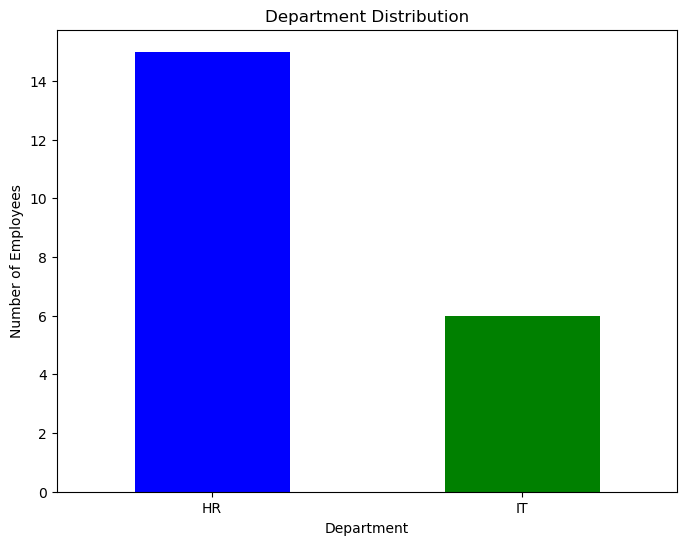

In [12]:
department_counts = data[['Department_hr', 'Department_it']].sum()

# Plotting department distribution
department_counts.plot(kind='bar', color=['blue', 'green'], figsize=(8, 6))

plt.title("Department Distribution")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(ticks=[0, 1], labels=["HR", "IT"], rotation=0)

plt.show()

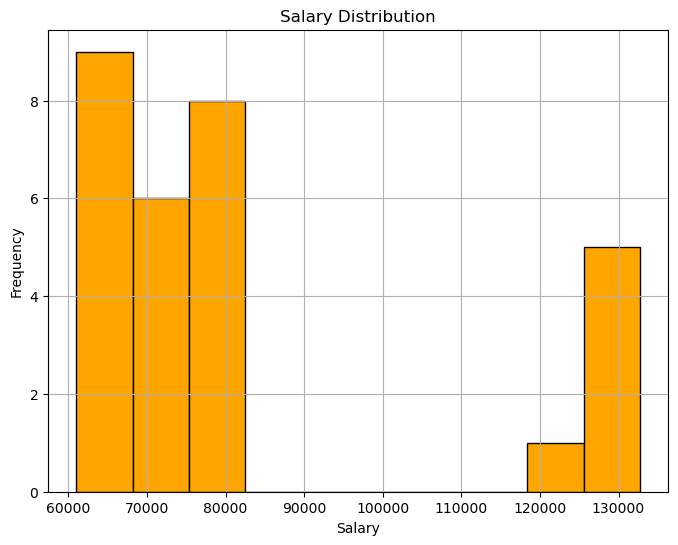

In [13]:
plt.figure(figsize=(8, 6))

plt.hist(data['Salary'], bins=10, color='orange', edgecolor='black')

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

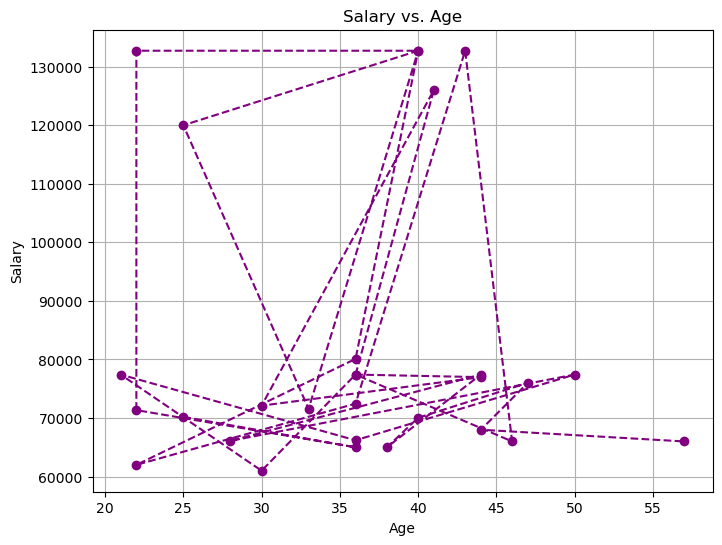

In [14]:
plt.figure(figsize=(8, 6))

plt.plot(data['Age'], data['Salary'], marker='o', linestyle='--', color='purple')

plt.title("Salary vs. Age")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.grid(True)

plt.show()

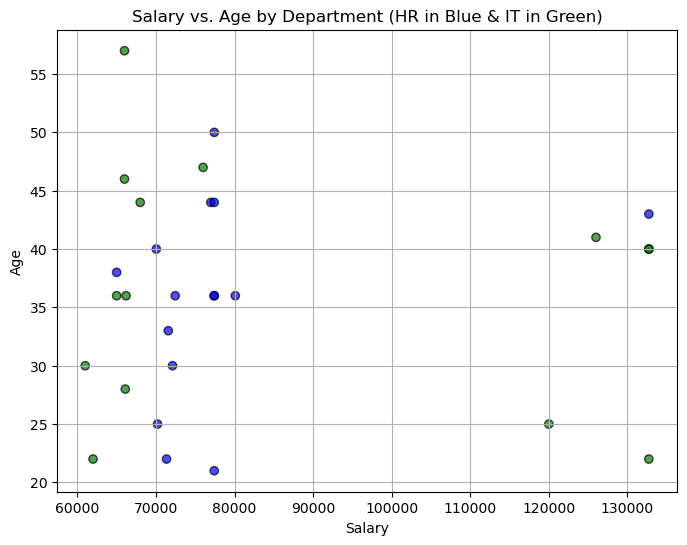

In [15]:
plt.figure(figsize=(8, 6))

colors = ['blue' if dept == 1 else 'green' for dept in data['Department_hr']]

plt.scatter(data['Salary'], data['Age'], c=colors, alpha=0.7, edgecolor='black')

plt.title("Salary vs. Age by Department (HR in Blue & IT in Green)")
plt.xlabel("Salary")
plt.ylabel("Age")

plt.grid(True)

plt.show()